# Model I
## Rozpoznawanie instrumentów za pomocą sieci CNN
### Bilbioteki

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score
import time
from model import InstrumentCNN
from trening import get_device, train_model
from przygotowanie_danych import (
    INSTRUMENTS,
    create_datasets,
    create_loaders
)

In [3]:
# Konfiguracja eksperymentu
epochs = 100
patience = 10
batch_size =32
learning_rate = 0.0005

dropout2 = 0.1
dropout3 = 0.3

threshold = 0.8

# Nazwa pliku z wagami zależna od konfiguracji eksperymentu
model_name = (
    f"cnn1_bs{batch_size}"
    f"_lr{learning_rate}"
    f"_do{dropout2}_{dropout3}.pth"
)

In [4]:
train_dataset, val_dataset, test_dataset = create_datasets()

train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset, batch_size=batch_size)

In [5]:
device = get_device()

model = InstrumentCNN(dropout2=dropout2, dropout3=dropout3).to(device)
criterion = nn.MultiLabelSoftMarginLoss()
optimizer = optim.Adam(model.parameters(),lr=learning_rate)

## Trening modelu

Do uczenia sieci wykorzystano standardowy optymalizator Adam. Zastosowano także mechanizm *Early stopping*, który zatrzymuje trening w przypadku braku 

In [6]:
start_time = time.perf_counter()
model, history, best_epoch, best_val_loss = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=epochs,
    patience=patience,
    model_name=model_name
)
training_time = time.perf_counter() - start_time

print(f"Czas treningu: {training_time / 60:.2f} min")

Epoka 1/100 | Train loss: 0.6494 | Val loss: 0.5842
Epoka 2/100 | Train loss: 0.5774 | Val loss: 0.5346
Epoka 3/100 | Train loss: 0.5434 | Val loss: 0.5242
Epoka 4/100 | Train loss: 0.5262 | Val loss: 0.5003
Epoka 5/100 | Train loss: 0.5134 | Val loss: 0.4826
Epoka 6/100 | Train loss: 0.4997 | Val loss: 0.4658
Epoka 7/100 | Train loss: 0.4877 | Val loss: 0.4505
Epoka 8/100 | Train loss: 0.4754 | Val loss: 0.4392
Epoka 9/100 | Train loss: 0.4663 | Val loss: 0.4363
Epoka 10/100 | Train loss: 0.4584 | Val loss: 0.4229
Epoka 11/100 | Train loss: 0.4503 | Val loss: 0.4130
Epoka 12/100 | Train loss: 0.4445 | Val loss: 0.4147
Epoka 13/100 | Train loss: 0.4369 | Val loss: 0.4082
Epoka 14/100 | Train loss: 0.4282 | Val loss: 0.3928
Epoka 15/100 | Train loss: 0.4225 | Val loss: 0.3928
Epoka 16/100 | Train loss: 0.4190 | Val loss: 0.3782
Epoka 17/100 | Train loss: 0.4136 | Val loss: 0.3761
Epoka 18/100 | Train loss: 0.4083 | Val loss: 0.3721
Epoka 19/100 | Train loss: 0.4040 | Val loss: 0.3710
Ep

In [7]:
instrument_names = list(INSTRUMENTS.values())

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits).cpu().numpy()
        predictions = (probabilities >= threshold).astype(int)
        true_labels = y.cpu().numpy().astype(int)

        print("Prawdopodobieństwa:")
        display(pd.DataFrame(probabilities, columns=instrument_names).round(3))
        
        print("Przewidywane etykiety:")
        display(pd.DataFrame(predictions, columns=instrument_names))
        
        print("Prawdziwe etykiety:")
        display(pd.DataFrame(true_labels, columns=instrument_names))

        break

Prawdopodobieństwa:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,0.955,0.360,0.762,1.000,0.986,0.536,0.926
1,0.371,0.474,0.987,1.000,0.032,0.101,0.174
2,0.019,0.997,0.004,1.000,0.013,0.700,0.021
3,0.146,0.442,0.730,1.000,0.008,0.291,0.971
4,0.923,0.227,0.341,1.000,0.914,0.912,0.121
5,1.000,0.174,0.309,0.000,0.147,0.102,0.999
6,0.022,0.151,0.957,0.000,1.000,0.206,0.396
7,0.234,0.645,0.702,1.000,0.001,0.838,0.915
8,0.999,0.751,0.033,0.000,0.007,0.033,0.998
9,0.691,0.967,0.561,0.000,1.000,0.205,0.975


Przewidywane etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,0,0,1,1,0,1
1,0,0,1,1,0,0,0
2,0,1,0,1,0,0,0
3,0,0,0,1,0,0,1
4,1,0,0,1,1,1,0
5,1,0,0,0,0,0,1
6,0,0,1,0,1,0,0
7,0,0,0,1,0,1,1
8,1,0,0,0,0,0,1
9,0,1,0,0,1,0,1


Prawdziwe etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,0,1,1,1,1,1
1,0,1,1,1,0,0,0
2,0,1,0,1,0,1,0
3,0,1,0,1,0,0,1
4,1,0,1,1,1,1,0
5,1,0,0,0,0,0,1
6,0,0,1,0,1,0,1
7,0,1,1,1,0,1,1
8,1,1,0,0,0,0,1
9,1,1,0,0,1,0,1


In [8]:
model.eval()

all_predictions = []
all_labels = []
val_loss = 0.0

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)
        loss = criterion(logits, y)

        val_loss += loss.item() * X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= threshold).float()

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(y.cpu().numpy())

val_loss /= len(val_loader.dataset)

all_predictions = np.concatenate(all_predictions, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

f1_micro = f1_score(all_labels, all_predictions, average="micro", zero_division=0)
f1_macro = f1_score(all_labels, all_predictions, average="macro", zero_division=0)
f1_per_instrument = f1_score(all_labels, all_predictions, average=None, zero_division=0)

print(f"Validation loss: {val_loss:.4f}")
print(f"Micro-F1: {f1_micro:.4f}")
print(f"Macro-F1: {f1_macro:.4f}")

results = pd.DataFrame({
    "Instrument": list(INSTRUMENTS.values()),
    "F1-score": f1_per_instrument
})

display(results.round(4))

Validation loss: 0.2229
Micro-F1: 0.8243
Macro-F1: 0.7967


,Instrument,F1-score
0,Gitara akustyczna,0.8228
1,Saksofon altowy,0.6735
2,Fortepian,0.7018
3,Perkusja,0.9945
4,Gitara basowa,0.9616
5,Flet,0.5362
6,Sekcja smyczkowa,0.8866


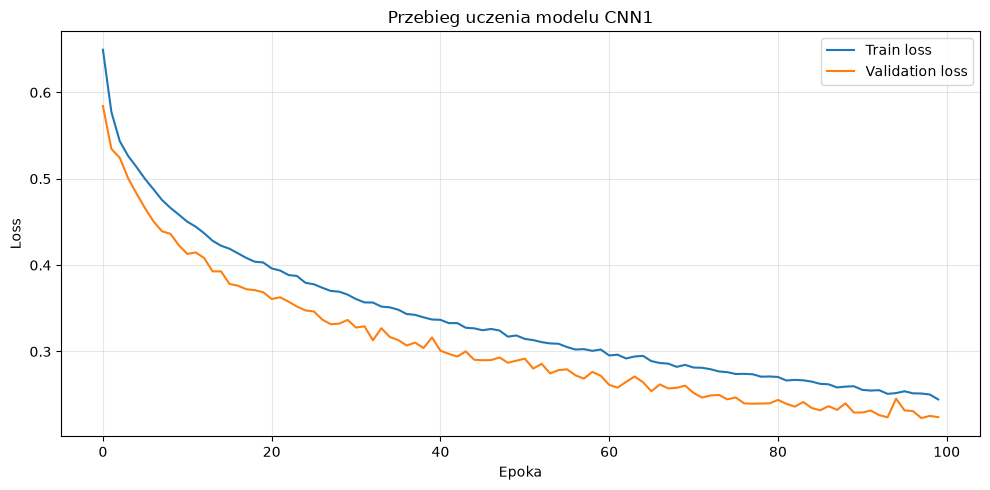

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.title("Przebieg uczenia modelu CNN1")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

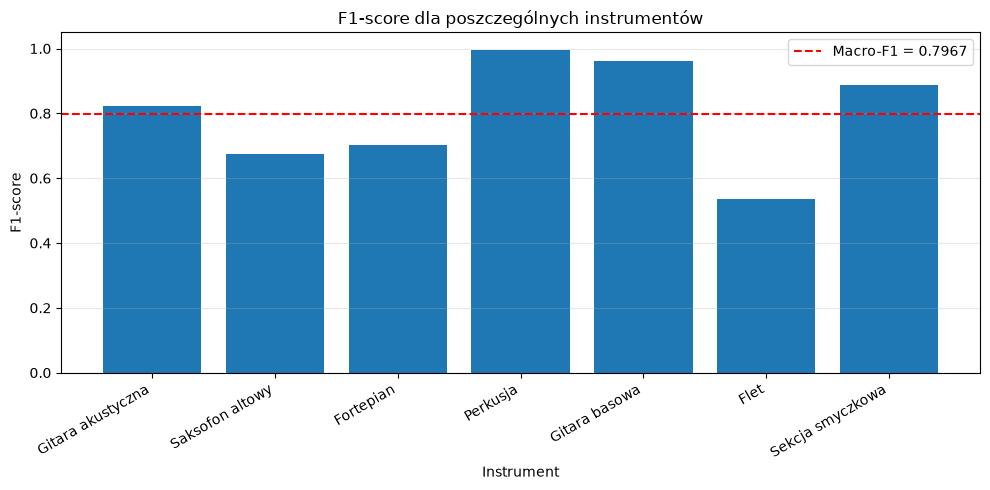

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(results["Instrument"], results["F1-score"])

plt.axhline(
    y=f1_macro,
    color="red",
    linestyle="--",
    label=f"Macro-F1 = {f1_macro:.4f}"
)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title("F1-score dla poszczególnych instrumentów")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics = pd.DataFrame({
    "Instrument": list(INSTRUMENTS.values()),
    "Precision": precision,
    "Recall": recall
})

display(metrics.round(4))

,Instrument,Precision,Recall
0,Gitara akustyczna,0.9861,0.7060
1,Saksofon altowy,0.9679,0.5164
2,Fortepian,0.9841,0.5453
3,Perkusja,1.0000,0.9892
4,Gitara basowa,0.9811,0.9430
5,Flet,0.9774,0.3695
6,Sekcja smyczkowa,0.9954,0.7993


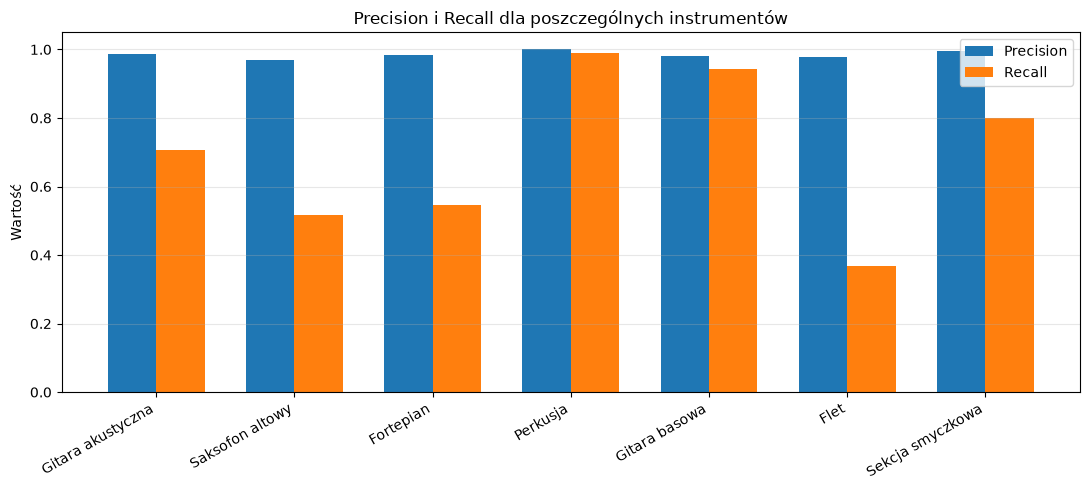

In [12]:
x = np.arange(len(INSTRUMENTS))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(x - width / 2, precision, width, label="Precision")
plt.bar(x + width / 2, recall, width, label="Recall")

plt.xticks(x, list(INSTRUMENTS.values()), rotation=30, ha="right")
plt.ylabel("Wartość")
plt.title("Precision i Recall dla poszczególnych instrumentów")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
results_dir = Path("wyniki")
results_dir.mkdir(exist_ok=True)

results_file = results_dir / "porownanie_eksperymentow.csv"

In [14]:
experiment = pd.DataFrame([{
    "Batch size": batch_size,
    "Learning rate": learning_rate,
    "Dropout 2": dropout2,
    "Dropout 3": dropout3,
    "Best epoch": best_epoch,
    "Best val loss": best_val_loss,
    "Micro-F1": f1_micro,
    "Macro-F1": f1_macro,
    # "Training time [min]": training_time / 60
}])

if results_file.exists():
    experiment.to_csv(results_file, mode="a", header=False, index=False)
else:
    experiment.to_csv(results_file, index=False)

print("Wyniki eksperymentu zapisano.")

Wyniki eksperymentu zapisano.


In [15]:
comparison = pd.read_csv(results_file)
display(comparison.round(4))

,Batch size,Learning rate,Dropout 2,Dropout 3,Best epoch,Best val loss,Micro-F1,Macro-F1
0,16,0.0010,0.2,0.5,16,0.4051,0.3724,0.1892
1,32,0.0010,0.2,0.5,20,0.4048,0.5695,0.4431
2,8,0.0010,0.2,0.5,20,0.3777,0.6051,0.5152
3,8,0.0005,0.2,0.5,30,0.3243,0.7111,0.6454
4,32,0.0005,0.2,0.5,29,0.3689,0.6172,0.5313
5,8,0.0005,0.3,0.5,29,0.3693,0.6033,0.5020
6,8,0.0005,0.1,0.3,30,0.2748,0.7995,0.7608
7,8,0.0005,0.1,0.3,99,0.1834,0.8858,0.8713
8,32,0.0005,0.1,0.3,98,0.2229,0.8243,0.7967
